Bike Sharing Demand Prediction
Dataset loaded successfully!
Number of records: 10886

Input features:
['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'hour', 'day', 'month', 'year', 'day_of_week']

Target variable: count

Training records: 8708
Testing records: 2178

Model training completed successfully!

MODEL PERFORMANCE
-----------------------------------
Mean Absolute Error (MAE): 47.62
Root Mean Squared Error: 74.16
R2 Score: 0.8838

ACTUAL VS PREDICTED RESULTS
                     Actual Count  Predicted Count
datetime                                          
2012-08-05 05:00:00            19               13
2012-08-05 06:00:00            19               25
2012-08-05 07:00:00            68               57
2012-08-05 08:00:00           108              155
2012-08-05 09:00:00           229              256
2012-08-05 10:00:00           364              392
2012-08-05 11:00:00           437              463
2012-08-05 12:00:00         

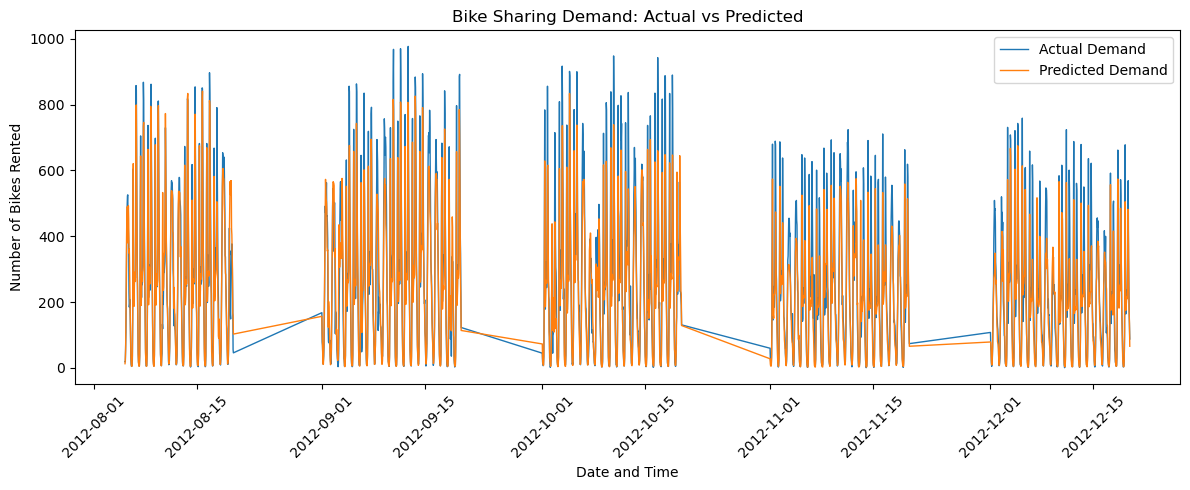


FEATURE IMPORTANCE
hour           0.5985
atemp          0.1046
year           0.0699
temp           0.0574
day_of_week    0.0418
workingday     0.0363
humidity       0.0278
month          0.0265
weather        0.0139
day            0.0095
windspeed      0.0075
season         0.0047
holiday        0.0015
dtype: float64


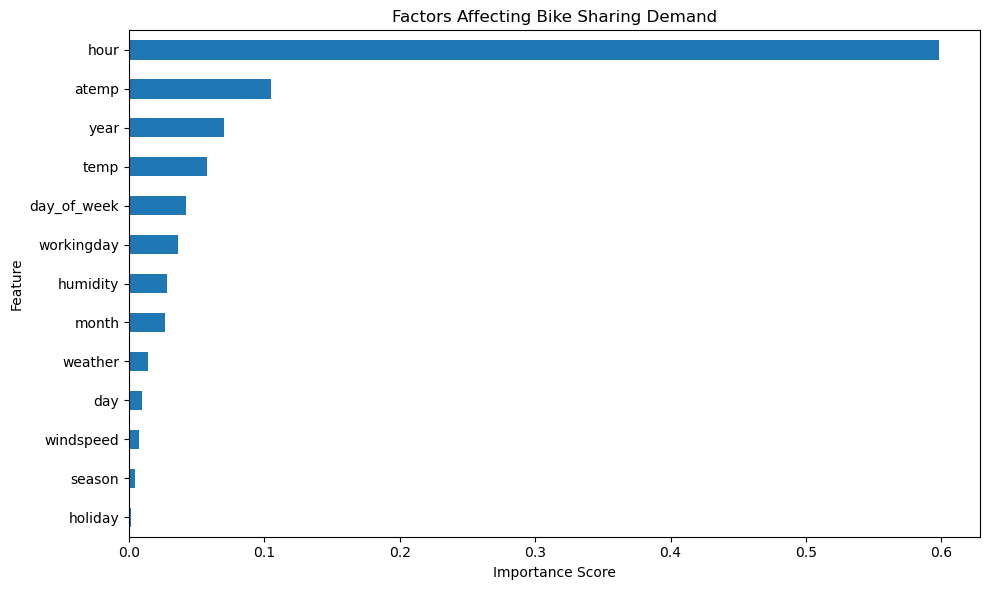


PREDICT DEMAND FOR A NEW OBSERVATION
-----------------------------------


Enter date and time (YYYY-MM-DD HH:MM):  2013-08-01 16:00:00
Season (1=Spring, 2=Summer, 3=Fall, 4=Winter):  2
Holiday (0=No, 1=Yes):  1
Working day (0=No, 1=Yes):  0
Weather (1=Clear, 2=Misty, 3=Light rain/snow, 4=Heavy rain/snow):  1
Temperature (Celsius):  28
Feels-like temperature (Celsius):  28
Humidity (0-100):  56
Wind speed:  0.0074



PREDICTION RESULT
Date and time: 2013-08-01 16:00:00
Expected number of bike rentals: 431


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_csv("Bike sharing.csv")

print("Bike Sharing Demand Prediction")
print("=" * 35)
print("Dataset loaded successfully!")
print("Number of records:", len(df))

df["datetime"] = pd.to_datetime(
    df["datetime"], errors="coerce"
)

df = df.dropna(subset=["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)

df["hour"] = df["datetime"].dt.hour
df["day"] = df["datetime"].dt.day
df["month"] = df["datetime"].dt.month
df["year"] = df["datetime"].dt.year
df["day_of_week"] = df["datetime"].dt.dayofweek

features = [
    "season",
    "holiday",
    "workingday",
    "weather",
    "temp",
    "atemp",
    "humidity",
    "windspeed",
    "hour",
    "day",
    "month",
    "year",
    "day_of_week"
]

X = df[features]
y = df["count"]

print("\nInput features:")
print(features)

print("\nTarget variable: count")

split_point = int(len(df) * 0.80)

X_train = X.iloc[:split_point]
X_test = X.iloc[split_point:]

y_train = y.iloc[:split_point]
y_test = y.iloc[split_point:]

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

model = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nModel training completed successfully!")

predictions = model.predict(X_test)
predictions = np.maximum(0, predictions)
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("\nMODEL PERFORMANCE")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")
results = pd.DataFrame({
    "Actual Count": y_test.values,
    "Predicted Count": np.round(predictions).astype(int)
}, index=df["datetime"].iloc[split_point:])

print("\nACTUAL VS PREDICTED RESULTS")
print(results.head(15))

results.to_csv("bike_sharing_predictions.csv")

print("\nPredictions saved to bike_sharing_predictions.csv")
plt.figure(figsize=(12, 5))

plt.plot(
    results.index,
    results["Actual Count"],
    label="Actual Demand",
    linewidth=1
)

plt.plot(
    results.index,
    results["Predicted Count"],
    label="Predicted Demand",
    linewidth=1
)

plt.xlabel("Date and Time")
plt.ylabel("Number of Bikes Rented")
plt.title("Bike Sharing Demand: Actual vs Predicted")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("\nFEATURE IMPORTANCE")
print(importance.round(4))

plt.figure(figsize=(10, 6))

importance.sort_values().plot(kind="barh")

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Factors Affecting Bike Sharing Demand")
plt.tight_layout()
plt.show()

print("\nPREDICT DEMAND FOR A NEW OBSERVATION")
print("-" * 35)

date_input = input(
    "Enter date and time (YYYY-MM-DD HH:MM): "
)

try:
    prediction_date = pd.to_datetime(date_input)

    season = int(input(
        "Season (1=Spring, 2=Summer, 3=Fall, 4=Winter): "
    ))

    holiday = int(input("Holiday (0=No, 1=Yes): "))
    workingday = int(input("Working day (0=No, 1=Yes): "))
    weather = int(input(
        "Weather (1=Clear, 2=Misty, 3=Light rain/snow, "
        "4=Heavy rain/snow): "
    ))

    temp = float(input("Temperature (Celsius): "))
    atemp = float(input("Feels-like temperature (Celsius): "))
    humidity = float(input("Humidity (0-100): "))
    windspeed = float(input("Wind speed: "))

    new_data = pd.DataFrame([{
        "season": season,
        "holiday": holiday,
        "workingday": workingday,
        "weather": weather,
        "temp": temp,
        "atemp": atemp,
        "humidity": humidity,
        "windspeed": windspeed,
        "hour": prediction_date.hour,
        "day": prediction_date.day,
        "month": prediction_date.month,
        "year": prediction_date.year,
        "day_of_week": prediction_date.dayofweek
    }], columns=features)

    if season not in [1, 2, 3, 4]:
        raise ValueError("Season must be between 1 and 4.")

    if holiday not in [0, 1] or workingday not in [0, 1]:
        raise ValueError("Holiday and workingday must be 0 or 1.")

    if weather not in [1, 2, 3, 4]:
        raise ValueError("Weather must be between 1 and 4.")

    if not 0 <= humidity <= 100:
        raise ValueError("Humidity must be between 0 and 100.")

    predicted_count = model.predict(new_data)[0]
    predicted_count = max(0, int(round(predicted_count)))

    print("\nPREDICTION RESULT")
    print("Date and time:", prediction_date)
    print("Expected number of bike rentals:", predicted_count)

except (ValueError, TypeError) as error:
    print("Invalid input:", error)
